IMPORT MODULES

In [56]:
import nltk
nltk.download('popular')
import pandas as pd
import string
from nltk.corpus import stopwords
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score,classification_report,confusion_matrix
from sklearn.feature_extraction.text import TfidfVectorizer

[nltk_data] Downloading collection 'popular'
[nltk_data]    | 
[nltk_data]    | Downloading package cmudict to /root/nltk_data...
[nltk_data]    |   Package cmudict is already up-to-date!
[nltk_data]    | Downloading package gazetteers to /root/nltk_data...
[nltk_data]    |   Package gazetteers is already up-to-date!
[nltk_data]    | Downloading package genesis to /root/nltk_data...
[nltk_data]    |   Package genesis is already up-to-date!
[nltk_data]    | Downloading package gutenberg to /root/nltk_data...
[nltk_data]    |   Package gutenberg is already up-to-date!
[nltk_data]    | Downloading package inaugural to /root/nltk_data...
[nltk_data]    |   Package inaugural is already up-to-date!
[nltk_data]    | Downloading package movie_reviews to
[nltk_data]    |     /root/nltk_data...
[nltk_data]    |   Package movie_reviews is already up-to-date!
[nltk_data]    | Downloading package names to /root/nltk_data...
[nltk_data]    |   Package names is already up-to-date!
[nltk_data]    | Do

LOAD DATASET

In [57]:
data=pd.read_csv("/content/Building Plagiarism checker using Machine Learning/dataset.csv")
data.head()

,Unnamed: 0,source_text,plagiarized_text,label
0,0,Researchers have discovered a new species of b...,Scientists have found a previously unknown but...,1
1,1,The moon orbits the Earth in approximately 27....,Our natural satellite takes around 27.3 days t...,1
2,2,Water is composed of two hydrogen atoms and on...,H2O consists of 2 hydrogen atoms and 1 oxygen ...,1
3,3,The history of Rome dates back to 753 BC.,Rome has a long history that can be traced bac...,1
4,4,Pluto was once considered the ninth planet in ...,"In the past, Pluto was classified as the ninth...",1


In [58]:
data['label'].value_counts()

,count
label,
0,187
1,183


In [59]:
data.shape

(370, 4)

CLEAN TEXT

In [60]:
def preprocess_text(text):
  #remove punctuation
  text=text.translate(str.maketrans("","",string.punctuation))
  #convert to lower case
  text=text.lower()
  #Remove stopwords
  stop_words=set(stopwords.words('english'))
  text=" ".join((word for word in text.split() if word not in stop_words))
  return text
preprocess_text("This is my %#$#$!?/text to use for dummy text")

'text use dummy text'

In [61]:
data['source_text']=data['source_text'].apply(preprocess_text)
data['plagiarized_text']=data['plagiarized_text'].apply(preprocess_text)

In [62]:
data

,Unnamed: 0,source_text,plagiarized_text,label
0,0,researchers discovered new species butterfly a...,scientists found previously unknown butterfly ...,1
1,1,moon orbits earth approximately 273 days,natural satellite takes around 273 days comple...,1
2,2,water composed two hydrogen atoms one oxygen atom,h2o consists 2 hydrogen atoms 1 oxygen atom,1
3,3,history rome dates back 753 bc,rome long history traced back 753 bc,1
4,4,pluto considered ninth planet solar system,past pluto classified ninth planet suns planet...,1
...,...,...,...,...
365,397,playing musical instruments enhances creativity,creativity enhanced playing musical instruments,0
366,398,studying history helps understanding present,understanding present aided studying history,0
367,399,listening classical music improve focus,focus improved listening classical music,0
368,400,practicing yoga enhances physical flexibility,physical flexibility enhanced practicing yoga,0


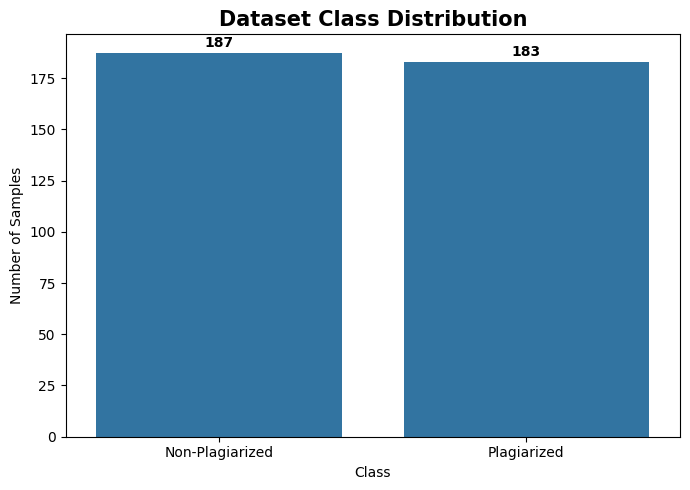

In [63]:
import matplotlib.pyplot as plt
import seaborn as sns

counts = data['label'].value_counts().sort_index()

plt.figure(figsize=(7,5))
ax = sns.barplot(
    x=['Non-Plagiarized', 'Plagiarized'],
    y=counts.values
)

plt.title('Dataset Class Distribution', fontsize=15, fontweight='bold')
plt.xlabel('Class')
plt.ylabel('Number of Samples')

for i, v in enumerate(counts.values):
    ax.text(i, v + 3, str(v), ha='center', fontweight='bold')

plt.tight_layout()
plt.show()

VECTORIZATION

In [64]:
tfidf_vectorizer=TfidfVectorizer()

X=tfidf_vectorizer.fit_transform(data['source_text'] + " " + data['plagiarized_text'])

In [65]:
Y=data['label']

TRAIN TEST SPLIT

In [66]:
X_train,X_test,Y_train,Y_test=train_test_split(X,Y,test_size=0.2,random_state=42)

APPLYING LOGISTIC REGRESSION

In [67]:
model=LogisticRegression()

model.fit(X_train,Y_train)
y_pred=model.predict(X_test)
print("accuracy ",accuracy_score(Y_test,y_pred))
print("classification",classification_report(Y_test,y_pred))
print("Confusion",confusion_matrix(Y_test,y_pred))

accuracy  0.8243243243243243
classification               precision    recall  f1-score   support

           0       0.79      0.86      0.82        35
           1       0.86      0.79      0.83        39

    accuracy                           0.82        74
   macro avg       0.83      0.83      0.82        74
weighted avg       0.83      0.82      0.82        74

Confusion [[30  5]
 [ 8 31]]


RANDOM FOREST

In [68]:
from sklearn.ensemble import RandomForestClassifier
model=RandomForestClassifier(n_estimators=100,random_state=42)

model.fit(X_train,Y_train)
y_pred=model.predict(X_test)
print("accuracy ",accuracy_score(Y_test,y_pred))
print("classification",classification_report(Y_test,y_pred))
print("Confusion",confusion_matrix(Y_test,y_pred))

accuracy  0.7972972972972973
classification               precision    recall  f1-score   support

           0       0.71      0.97      0.82        35
           1       0.96      0.64      0.77        39

    accuracy                           0.80        74
   macro avg       0.83      0.81      0.79        74
weighted avg       0.84      0.80      0.79        74

Confusion [[34  1]
 [14 25]]


NAIVE BAYES *MODEL*

In [69]:
from sklearn.naive_bayes import MultinomialNB
model=MultinomialNB()

model.fit(X_train,Y_train)
y_pred=model.predict(X_test)
print("accuracy ",accuracy_score(Y_test,y_pred))
print("classification",classification_report(Y_test,y_pred))
print("Confusion",confusion_matrix(Y_test,y_pred))

accuracy  0.8648648648648649
classification               precision    recall  f1-score   support

           0       0.86      0.86      0.86        35
           1       0.87      0.87      0.87        39

    accuracy                           0.86        74
   macro avg       0.86      0.86      0.86        74
weighted avg       0.86      0.86      0.86        74

Confusion [[30  5]
 [ 5 34]]


SUPPORT VECTOR MACHINE

In [70]:
from sklearn.svm import SVC

model=SVC(kernel='linear',random_state=42)

model.fit(X_train,Y_train)
y_pred=model.predict(X_test)
print("accuracy ",accuracy_score(Y_test,y_pred))
print("classification",classification_report(Y_test,y_pred))
print("Confusion",confusion_matrix(Y_test,y_pred))

accuracy  0.8783783783783784
classification               precision    recall  f1-score   support

           0       0.86      0.89      0.87        35
           1       0.89      0.87      0.88        39

    accuracy                           0.88        74
   macro avg       0.88      0.88      0.88        74
weighted avg       0.88      0.88      0.88        74

Confusion [[31  4]
 [ 5 34]]


**MODEL ACCURACY COMPARISION**

Model Accuracy Results:


,Model,Accuracy
0,Logistic Regression,0.824324
1,Random Forest,0.797297
2,Naive Bayes,0.864865
3,SVM,0.878378


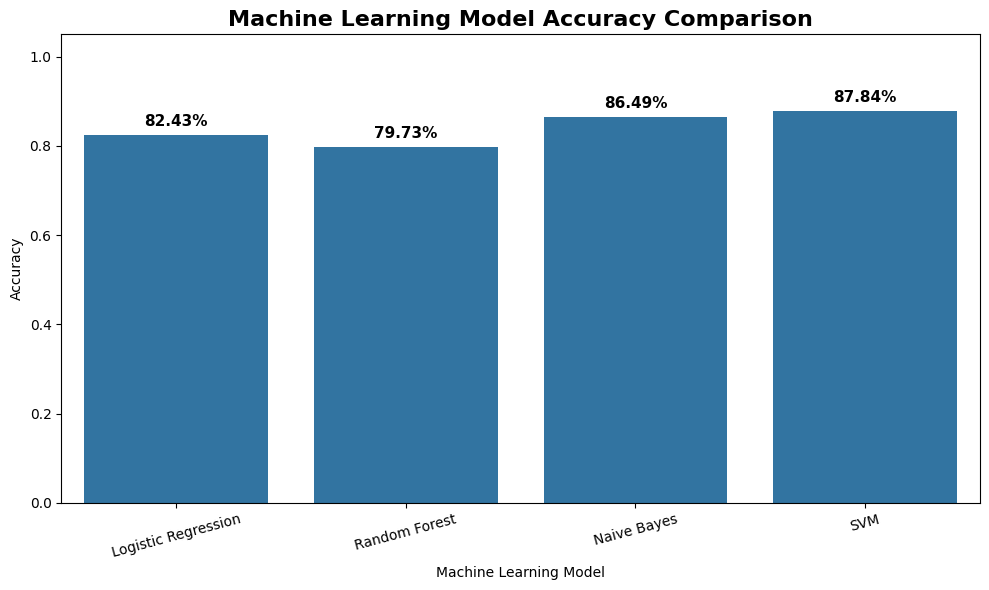

In [71]:
# ==========================================
# MODEL ACCURACY COMPARISON
# ==========================================

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score


# Define the models
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000),
    'Random Forest': RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ),
    'Naive Bayes': MultinomialNB(),
    'SVM': SVC(kernel='linear', random_state=42)
}


# Train each model and calculate accuracy
results = []

for name, model_temp in models.items():

    model_temp.fit(X_train, Y_train)

    predictions = model_temp.predict(X_test)

    accuracy = accuracy_score(Y_test, predictions)

    results.append({
        'Model': name,
        'Accuracy': accuracy
    })


# Convert results into DataFrame
results_df = pd.DataFrame(results)

print("Model Accuracy Results:")
display(results_df)


# ==========================================
# CREATE GRAPH
# ==========================================

plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=results_df,
    x='Model',
    y='Accuracy'
)

plt.title(
    'Machine Learning Model Accuracy Comparison',
    fontsize=16,
    fontweight='bold'
)

plt.xlabel('Machine Learning Model')
plt.ylabel('Accuracy')

plt.ylim(0, 1.05)

plt.xticks(rotation=15)

# Display accuracy above each bar
for i, value in enumerate(results_df['Accuracy']):
    ax.text(
        i,
        value + 0.02,
        f'{value:.2%}',
        ha='center',
        fontsize=11,
        fontweight='bold'
    )

plt.tight_layout()
plt.show()

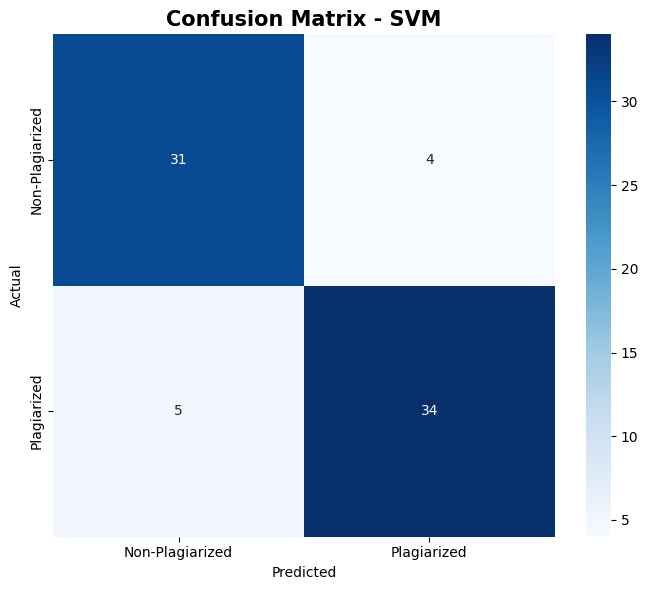

In [72]:
from sklearn.metrics import confusion_matrix

final_model = SVC(kernel='linear', random_state=42)

final_model.fit(X_train, Y_train)

y_pred = final_model.predict(X_test)

cm = confusion_matrix(Y_test, y_pred)

plt.figure(figsize=(7,6))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Non-Plagiarized', 'Plagiarized'],
    yticklabels=['Non-Plagiarized', 'Plagiarized']
)

plt.title('Confusion Matrix - SVM',
          fontsize=15, fontweight='bold')

plt.xlabel('Predicted')
plt.ylabel('Actual')

plt.tight_layout()
plt.show()

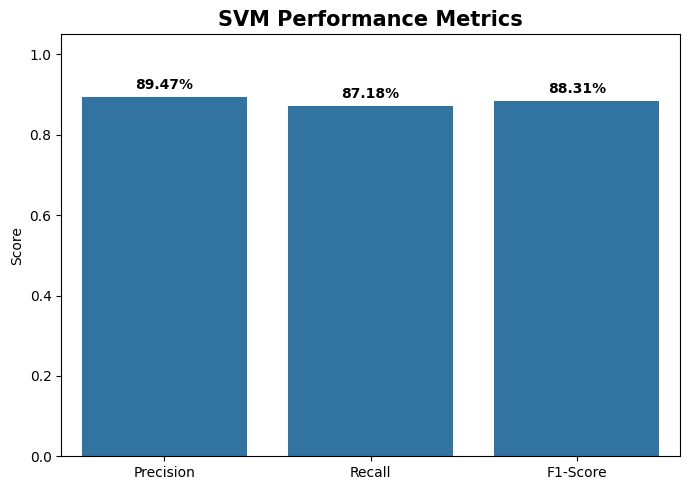

In [73]:
from sklearn.metrics import precision_score, recall_score, f1_score

precision = precision_score(Y_test, y_pred)
recall = recall_score(Y_test, y_pred)
f1 = f1_score(Y_test, y_pred)

metrics = {
    'Precision': precision,
    'Recall': recall,
    'F1-Score': f1
}

plt.figure(figsize=(7,5))

ax = sns.barplot(
    x=list(metrics.keys()),
    y=list(metrics.values())
)

plt.title('SVM Performance Metrics',
          fontsize=15, fontweight='bold')

plt.ylabel('Score')
plt.ylim(0, 1.05)

for i, v in enumerate(metrics.values()):
    ax.text(i, v + 0.02, f'{v:.2%}',
            ha='center', fontweight='bold')

plt.tight_layout()
plt.show()

SAVE SVM AND VECTORIZER

In [74]:
import pickle
pickle.dump(model,open('model.pkl','wb'))
pickle.dump(tfidf_vectorizer,open('tfidf_vectorizer.pkl','wb'))

LOAD MODEL AND VECTORIZER

In [75]:
model=pickle.load(open('model.pkl','rb'))
tfidf_vectorizer=pickle.load(open('tfidf_vectorizer.pkl','rb'))

DETECTION SYSTEM

In [76]:
def detect(input_text):
   #vectorize the text
   vectorized_text=tfidf_vectorizer.transform([input_text])
   #then will do prediction by model
   result=model.predict(vectorized_text)
   return "Plagiarism Detected" if result[0]==1 else "No plagiarism"

In [77]:
#example (It is a Plagiarized text)
input_text='Researchers have discovered a new species of butterfly in the Amazon rainforest.'
detect(input_text)

'Plagiarism Detected'

In [78]:
#example (It has no plagiarism)
input_text='Playing musical instruments enchances creativity.'
detect(input_text)

'No plagiarism'

In [79]:
#example (It has no plagiarism)
input_text='Practicing yoga enchances physical flexibilty'
detect(input_text)

'No plagiarism'

In [80]:
#sklearn version
import sklearn
sklearn.__version__

'1.6.1'